Name : Luqman Khan

SID : S202266054

Section : V1

Course Code: CS4152

Semester: Fall 2026   

Sumitted to: Dr. Jameel Ahmad

Course Title: Deep Learning and Neural Networks

                                                              CLASS ACTIVITY 1

# Task 1: Taxi Fare Prediction

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv('/content/taxi-fares.csv')
df

,key,fare_amount,pickup_datetime,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,passenger_count
0,2014-06-15 17:11:00.000000107,7.0,2014-06-15 17:11:00 UTC,-73.995420,40.759662,-73.987607,40.751247,1
1,2011-03-14 22:43:00.00000095,4.9,2011-03-14 22:43:00 UTC,-73.993552,40.731110,-73.998497,40.737200,5
2,2011-02-14 15:14:00.00000067,6.1,2011-02-14 15:14:00 UTC,-73.972380,40.749527,-73.990638,40.745328,1
3,2009-10-29 11:29:00.00000040,6.9,2009-10-29 11:29:00 UTC,-73.973703,40.763542,-73.984253,40.758603,5
4,2011-07-02 10:38:00.00000028,10.5,2011-07-02 10:38:00 UTC,-73.921262,40.743615,-73.967383,40.765162,1
...,...,...,...,...,...,...,...,...
55363,2011-09-18 19:58:26.0000004,49.8,2011-09-18 19:58:26 UTC,-73.954218,40.781272,-73.790650,40.644147,1
55364,2011-02-05 16:22:00.000000112,9.7,2011-02-05 16:22:00 UTC,-74.000117,40.732792,-73.974612,40.749842,1
55365,2010-06-14 09:49:26.0000005,8.9,2010-06-14 09:49:26 UTC,-73.994161,40.751109,-73.973510,40.757730,1
55366,2015-06-08 21:54:03.0000002,3.5,2015-06-08 21:54:03 UTC,-73.995331,40.759766,-73.990479,40.766396,1


**❼ Filter data for single-passenger trips only**

In [6]:
df = df[df['passenger_count']==1]
print("After sinngle Passengerr filter ", df.shape)

After sinngle Passengerr filter  (38233, 8)


In [7]:

df = df.drop(['key', 'passenger_count'], axis=1)


**❼ Extract features: day of week, pickup hour, and distance traveled**

In [8]:
#  Convert the column to datetime
df['pickup_datetime'] = pd.to_datetime(df['pickup_datetime'])

df['day_of_week'] = df['pickup_datetime'].dt.weekday

df['pickup_time'] = df['pickup_datetime'].dt.hour



**❼ Remove outliers: distance between 1.0–10.0 miles, fare between ✩0–✩50**

In [9]:

dx = (
    df['dropoff_longitude'] -
    df['pickup_longitude']
) * 54.6

dy = (
    df['dropoff_latitude'] -
    df['pickup_latitude']
) * 69.0

df['distance'] = np.sqrt(dx**2 + dy**2)
print(df['distance'])


0         0.720497
2         1.038136
4         2.924341
5         4.862893
8         2.603493
           ...    
55363    13.010833
55364     1.822990
55365     1.216580
55366     0.528645
55367     0.740314
Name: distance, Length: 38233, dtype: float64


**Remove raw date and coordinate columns**

In [10]:

df = df.drop([
    'pickup_datetime',
    'pickup_longitude',
    'pickup_latitude',
    'dropoff_longitude',
    'dropoff_latitude'
], axis=1)


In [11]:

df = df[
    (df['distance'] > 1.0) &
    (df['distance'] < 10.0)
]

df = df[
    (df['fare_amount'] > 0.0) &
    (df['fare_amount'] < 50.0)
]

print('After outlier removal:', df.shape)

df.head()


After outlier removal: (23298, 4)


,fare_amount,day_of_week,pickup_time,distance
2,6.1,0,15,1.038136
4,10.5,5,10,2.924341
5,15.3,4,20,4.862893
8,7.7,5,1,2.603493
9,8.9,3,16,1.365739


**This keeps distances between 1 and 10 miles and fares between $0 and $50, following the notebook's conditions.**

In [12]:

x = df[['day_of_week', 'pickup_time', 'distance']]

y = df['fare_amount']

print(x.shape, y.shape)


(23298, 3) (23298,)


x contains the three input features.

y contains the taxi fare that the model must predict.

# Task 1 : b —> Build the neural network





In [13]:

import os, time, random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    r2_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_seed()
sns.set()

os.makedirs('results', exist_ok=True)

print('TensorFlow version:', tf.__version__)


TensorFlow version: 2.21.0


Understand it:
- numpy and pandas handle data and calculations.
- matplotlib and seaborn make graphs.
- tensorflow builds and trains neural networks.
- Sequential arranges layers in order.
- Dense creates fully connected layers.
- Dropout supports regularization.
- EarlyStopping and ModelCheckpoint are used in Task 5.
- set_seed() makes experiments more reproducible.
- results is the folder where the notebook saves CSV results.

In [14]:

def build_taxi_model(width=512):

    m = Sequential()

    m.add(Dense(width, activation='relu', input_dim=3))

    m.add(Dense(width, activation='relu'))

    m.add(Dense(1))

    m.compile(
        optimizer='adam',
        loss='mae',
        metrics=['mae']
    )

    return m



The architecture must match the notebook:
- Input: 3 features.
- Hidden layer 1: 512 neurons, ReLU.
- Hidden layer 2: 512 neurons, ReLU.
- Output: 1 neuron, with no activation.

In [15]:

set_seed()

model = build_taxi_model(512)

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 512)            │         2,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 512)            │       262,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 265,217 (1.01 MB)

 Trainable params: 265,217 (1.01 MB)

 Non-trainable params: 0 (0.00 B)

model.summary() displays the layers and the number of trainable parameters.

# Q1:part(c) Model Compilation and Training:

**❼ Train for 100 epochs with batch size of 100**

In [16]:
hist = model.fit(
    x,
    y,
    validation_split=0.2,
    epochs=100,
    batch_size=100,
    verbose=1
)

pd.DataFrame(hist.history).to_csv(
    'results/task1_history.csv',
    index=False
)

Epoch 1/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - loss: 2.8967 - mae: 2.8967 - val_loss: 2.3768 - val_mae: 2.3768
Epoch 2/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.3911 - mae: 2.3911 - val_loss: 2.3637 - val_mae: 2.3637
Epoch 3/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.3868 - mae: 2.3868 - val_loss: 2.3600 - val_mae: 2.3600
Epoch 4/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2.3793 - mae: 2.3793 - val_loss: 2.3587 - val_mae: 2.3587
Epoch 5/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - loss: 2.3800 - mae: 2.3800 - val_loss: 2.3480 - val_mae: 2.3480
Epoch 6/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - loss: 2.3706 - mae: 2.3706 - val_loss: 2.3462 - val_mae: 2.3462
Epoch 7/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 2.3694 - mae: 2.3694 - val_loss: 2.3444 - val_mae: 2.3444
Epoch 8/100
187/187 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 2.3582 - mae: 2.3582 - val_loss: 2.3355 - val_mae: 2.3355
Epoch 9/100
187/187 ━━━━━━━━━━━━━━━━━━━━

# Task 1d — Evaluate the model

**Plot training and validation MAE**

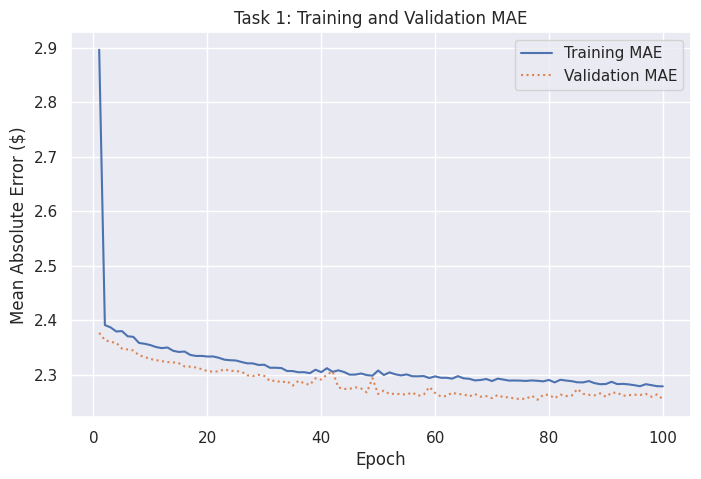

Final training MAE  : 2.279
Final validation MAE: 2.255


In [17]:

err = hist.history['mae']
val_err = hist.history['val_mae']

epochs = range(1, len(err) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, err, '-', label='Training MAE')
plt.plot(epochs, val_err, ':', label='Validation MAE')

plt.title('Task 1: Training and Validation MAE')
plt.xlabel('Epoch')
plt.ylabel('Mean Absolute Error ($)')

plt.legend()
plt.show()

print('Final training MAE  : %.3f' % err[-1])
print('Final validation MAE: %.3f' % val_err[-1])


Both training and validation MAE drop sharply in the first few epochs and then level off around $2.26–$2.28, so the model has converged and is learning stably. The two curves stay very close (final training MAE 2.279 vs validation 2.255), which means there is no overfitting. Validation is slightly lower than training because Keras averages training MAE over the epoch while the weights are still changing, whereas validation is measured at the end of the epoch.

An average error of about $2.26 per fare is moderate. The model uses only day, hour and distance, so it cannot capture traffic, route or tolls, and the error stops improving after about 60 epochs.

Calculate **R²** and compare Friday with **Saturday:** **bold text**

In [18]:

print(
    'R2 score:',
    r2_score(y, model.predict(x, verbose=0))
)

friday = model.predict(
    np.array([[4, 17, 2.0]]),
    verbose=0
)[0][0]

saturday = model.predict(
    np.array([[5, 17, 2.0]]),
    verbose=0
)[0][0]

print('2-mile trip, Friday   5 PM: $%.2f' % friday)
print('2-mile trip, Saturday 5 PM: $%.2f' % saturday)

print(
    'Difference (Fri - Sat): $%.2f'
    % (friday - saturday)
)


R2 score: 0.7511731109197979
2-mile trip, Friday   5 PM: $10.66
2-mile trip, Saturday 5 PM: $10.45
Difference (Fri - Sat): $0.21


Analysis questions from the original notebook:
1. Is validation MAE close to training MAE? Explain whether the results suggest overfitting.
2. Which predicted fare is higher, Friday or Saturday? Discuss whether the result makes sense.
3. What does your R² score mean?
Use the actual values printed by your notebook. Remember that this R² is calculated on the same data used for training, so it is not a reliable estimate of performance on unseen trips.

# Task 1 **e** — **Experiments**

Define the experiment function

In [19]:

EXP_EPOCHS = 30

def run_taxi(
    width=512,
    batch_size=100,
    epochs=EXP_EPOCHS,
    seed=0
):
    set_seed(seed)

    m = build_taxi_model(width)

    t0 = time.time()

    h = m.fit(
        x,
        y,
        validation_split=0.2,
        epochs=epochs,
        batch_size=batch_size,
        verbose=0
    )

    secs = time.time() - t0

    r2 = r2_score(
        y,
        m.predict(x, verbose=0)
    )

    return {
        'width': width,
        'batch_size': batch_size,
        'epochs': epochs,
        'seed': seed,
        'train_MAE': h.history['mae'][-1],
        'val_MAE': h.history['val_mae'][-1],
        'R2': r2,
        'time_sec': secs
    }

results = []


Experiment with three random seeds

In [20]:

for s in [1, 2, 3]:

    r = run_taxi(512, 100, seed=s)

    r['experiment'] = 'variance'

    results.append(r)

    print(r)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.317284107208252, 'val_MAE': 2.323918104171753, 'R2': 0.7345589495580659, 'time_sec': 64.87463593482971, 'experiment': 'variance'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 100, 'epochs': 30, 'seed': 2, 'train_MAE': 2.312814950942993, 'val_MAE': 2.3046882152557373, 'R2': 0.7426349647492708, 'time_sec': 65.48963499069214, 'experiment': 'variance'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 100, 'epochs': 30, 'seed': 3, 'train_MAE': 2.318885087966919, 'val_MAE': 2.297452688217163, 'R2': 0.7395073901213433, 'time_sec': 63.03880953788757, 'experiment': 'variance'}


Compare hidden-layer widths

In [21]:

for w in [128, 256, 512, 1024]:

    r = run_taxi(
        width=w,
        batch_size=100,
        seed=1
    )

    r['experiment'] = 'width'

    results.append(r)

    print(r)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 128, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.3149404525756836, 'val_MAE': 2.312802791595459, 'R2': 0.7355359463194067, 'time_sec': 25.776077270507812, 'experiment': 'width'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 256, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.310946226119995, 'val_MAE': 2.317631721496582, 'R2': 0.7361128584531524, 'time_sec': 35.874393939971924, 'experiment': 'width'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.317284107208252, 'val_MAE': 2.323918104171753, 'R2': 0.7345589495580659, 'time_sec': 66.89594602584839, 'experiment': 'width'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 1024, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.3260059356689453, 'val_MAE': 2.330915689468384, 'R2': 0.7337498446492221, 'time_sec': 246.82105112075806, 'experiment': 'width'}


Compare batch sizes

In [22]:

for b in [32, 100, 500, 1000]:

    r = run_taxi(
        width=512,
        batch_size=b,
        seed=1
    )

    r['experiment'] = 'batch_size'

    results.append(r)

    print(r)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 32, 'epochs': 30, 'seed': 1, 'train_MAE': 2.3201115131378174, 'val_MAE': 2.312971830368042, 'R2': 0.7425756361283126, 'time_sec': 136.2902524471283, 'experiment': 'batch_size'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 100, 'epochs': 30, 'seed': 1, 'train_MAE': 2.317284107208252, 'val_MAE': 2.323918104171753, 'R2': 0.7345589495580659, 'time_sec': 60.95749306678772, 'experiment': 'batch_size'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 500, 'epochs': 30, 'seed': 1, 'train_MAE': 2.314020872116089, 'val_MAE': 2.3203887939453125, 'R2': 0.7334055055686401, 'time_sec': 36.44612169265747, 'experiment': 'batch_size'}


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


{'width': 512, 'batch_size': 1000, 'epochs': 30, 'seed': 1, 'train_MAE': 2.31742262840271, 'val_MAE': 2.3277413845062256, 'R2': 0.7290510307573445, 'time_sec': 26.64217519760132, 'experiment': 'batch_size'}


Create the experiment summary table

In [23]:

summary = pd.DataFrame(results)[[
    'experiment',
    'width',
    'batch_size',
    'epochs',
    'seed',
    'train_MAE',
    'val_MAE',
    'R2',
    'time_sec'
]].round(3)

summary.to_csv(
    'results/task1_experiments.csv',
    index=False
)

summary


,experiment,width,batch_size,epochs,seed,train_MAE,val_MAE,R2,time_sec
0,variance,512,100,30,1,2.317,2.324,0.735,64.875
1,variance,512,100,30,2,2.313,2.305,0.743,65.490
2,variance,512,100,30,3,2.319,2.297,0.740,63.039
3,width,128,100,30,1,2.315,2.313,0.736,25.776
4,width,256,100,30,1,2.311,2.318,0.736,35.874
5,width,512,100,30,1,2.317,2.324,0.735,66.896
6,width,1024,100,30,1,2.326,2.331,0.734,246.821
7,batch_size,512,32,30,1,2.320,2.313,0.743,136.290
8,batch_size,512,100,30,1,2.317,2.324,0.735,60.957
9,batch_size,512,500,30,1,2.314,2.320,0.733,36.446
